# 问题 2：音乐相似度

用音频特征开发「音乐相似度」度量，验证**同流派内艺术家是否比跨流派更相似**。

**方法：**
1. 选 10 个连续特征做 Z-score 标准化（`key`/`mode` 是类别，`popularity` 不进距离）
2. 艺术家画像 = `data_by_artist` 的特征均值
3. 距离 = 欧氏距离；相似度 `S = 1/(1+d)`
4. 比较同流派对 vs 跨流派对的相似度，用**置换检验**排除偶然性

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 100

artists = pd.read_csv('output/artists.csv', dtype=str)

FEATURES = ['danceability', 'energy', 'valence', 'tempo', 'loudness',
            'acousticness', 'instrumentalness', 'liveness', 'speechiness', 'duration_ms']

# 转数值
for f in FEATURES:
    artists[f] = pd.to_numeric(artists[f], errors='coerce')

print('artists:', artists.shape)
print('有流派标签的艺术家:', (artists['genre'] != 'Unknown').sum())

artists: (5854, 18)
有流派标签的艺术家: 5599


## 1. Z-score 标准化

In [2]:
Z = artists[FEATURES].copy()
mu = Z.mean(); sd = Z.std()
Z = (Z - mu) / sd
artists = pd.concat([artists, Z.add_suffix('_z')], axis=1)
Z_FEATURES = [f + '_z' for f in FEATURES]

print('标准化完成，均值≈0，标准差≈1：')
print(Z.mean().round(3).to_dict())

标准化完成，均值≈0，标准差≈1：
{'danceability': 0.0, 'energy': 0.0, 'valence': 0.0, 'tempo': 0.0, 'loudness': -0.0, 'acousticness': -0.0, 'instrumentalness': 0.0, 'liveness': -0.0, 'speechiness': 0.0, 'duration_ms': -0.0}


## 2. 相似度函数

In [3]:
Zmat = artists[Z_FEATURES].values

def similarity(z_i, z_j):
    d = np.linalg.norm(z_i - z_j)
    return 1.0 / (1.0 + d)

def sim_by_idx(i, j):
    return similarity(Zmat[i], Zmat[j])

# 演示：两个 Jazz 艺术家 vs 一个 Jazz 一个 Pop/Rock
jazz_idx = artists[artists['genre'] == 'Jazz'].index
rock_idx = artists[artists['genre'] == 'Pop/Rock'].index
a, b = jazz_idx[:2]
c = rock_idx[0]
print(f'Jazz-Jazz 相似度 = {sim_by_idx(a, b):.4f}')
print(f'Jazz-Pop/Rock 相似度 = {sim_by_idx(a, c):.4f}')

Jazz-Jazz 相似度 = 0.5884
Jazz-Pop/Rock 相似度 = 0.2797


## 3. 同流派 vs 跨流派（采样比较）

同流派平均相似度 = 0.2289 ± 0.0844
跨流派平均相似度 = 0.1865 ± 0.0695
差值 = 0.0424


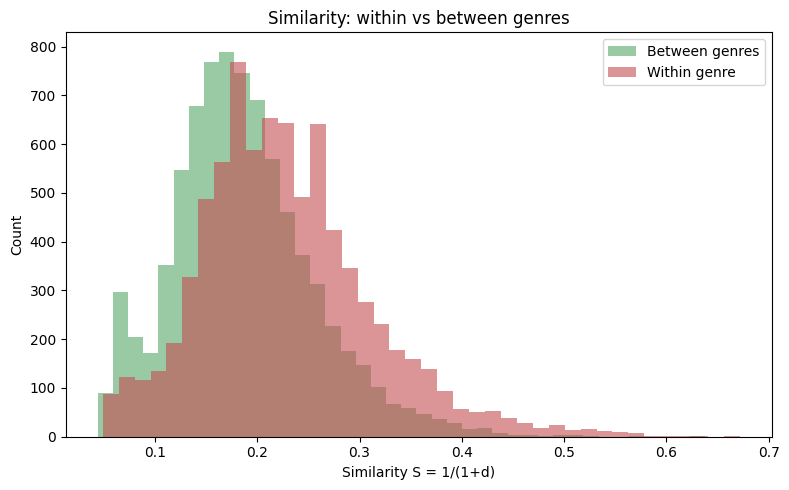

In [4]:
rng = np.random.default_rng(42)

labeled = artists[artists['genre'] != 'Unknown'].reset_index(drop=True)
labeled = labeled[labeled[Z_FEATURES].notna().all(axis=1)].reset_index(drop=True)
Lmat = labeled[Z_FEATURES].values
genres = labeled['genre'].values

genre_to_idx = {}
for i, g in enumerate(genres):
    genre_to_idx.setdefault(g, []).append(i)
genre_list = list(genre_to_idx.keys())

def sample_pairs(n_pairs, same):
    """采样 n_pairs 个艺术家对；same=True 同流派，False 跨流派"""
    pairs = []
    while len(pairs) < n_pairs:
        if same:
            g = genre_list[rng.integers(len(genre_list))]
            if len(genre_to_idx[g]) < 2:
                continue
            i, j = rng.choice(genre_to_idx[g], 2, replace=False)
        else:
            g1, g2 = rng.choice(genre_list, 2, replace=False)
            i = rng.choice(genre_to_idx[g1]); j = rng.choice(genre_to_idx[g2])
        pairs.append((i, j))
    return pairs

N = 8000
same_pairs = sample_pairs(N, True)
diff_pairs = sample_pairs(N, False)

def mean_sim(pairs):
    s = [similarity(Lmat[i], Lmat[j]) for i, j in pairs]
    return np.array(s)

same_sim = mean_sim(same_pairs)
diff_sim = mean_sim(diff_pairs)

print(f'同流派平均相似度 = {same_sim.mean():.4f} ± {same_sim.std():.4f}')
print(f'跨流派平均相似度 = {diff_sim.mean():.4f} ± {diff_sim.std():.4f}')
print(f'差值 = {same_sim.mean() - diff_sim.mean():.4f}')

plt.figure(figsize=(8, 5))
plt.hist(diff_sim, bins=40, alpha=0.6, label='Between genres', color='#55A868')
plt.hist(same_sim, bins=40, alpha=0.6, label='Within genre', color='#C44E52')
plt.xlabel('Similarity S = 1/(1+d)')
plt.ylabel('Count')
plt.title('Similarity: within vs between genres')
plt.legend()
plt.tight_layout(); plt.show()

## 4. 置换检验（显著性）

打乱流派标签重算「组内-组间」相似度差，检验真实差是否显著。

真实差值 = 0.0424
置换分布均值 = 0.0000，标准差 = 0.0026
p 值 ≈ 0.0000


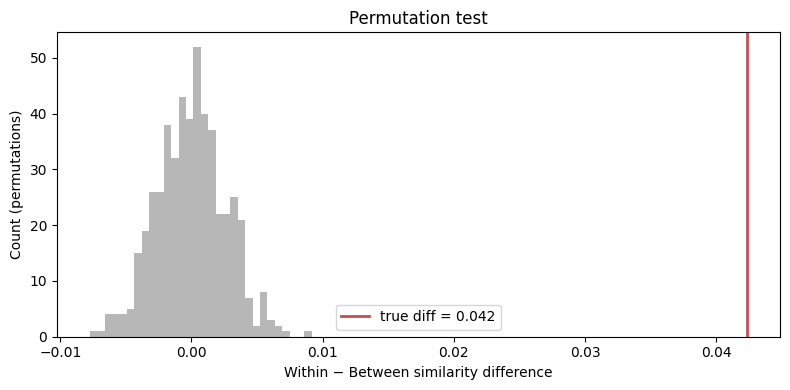

In [5]:
true_diff = same_sim.mean() - diff_sim.mean()

n_perm = 500
perm_diffs = []
for _ in range(n_perm):
    # 打乱标签
    perm_labels = rng.permutation(genres)
    perm_genre_idx = {}
    for i, g in enumerate(perm_labels):
        perm_genre_idx.setdefault(g, []).append(i)
    perm_genre_list = list(perm_genre_idx.keys())
    # 采样同/跨流派对（复用原采样结构，只按新标签分组）
    p_same, p_diff = [], []
    while len(p_same) < 2000 or len(p_diff) < 2000:
        if len(p_same) < 2000:
            g = perm_genre_list[rng.integers(len(perm_genre_list))]
            if len(perm_genre_idx[g]) >= 2:
                i, j = rng.choice(perm_genre_idx[g], 2, replace=False)
                p_same.append((i, j))
        if len(p_diff) < 2000:
            g1, g2 = rng.choice(perm_genre_list, 2, replace=False)
            i = rng.choice(perm_genre_idx[g1]); j = rng.choice(perm_genre_idx[g2])
            p_diff.append((i, j))
    s_same = np.mean([similarity(Lmat[i], Lmat[j]) for i, j in p_same])
    s_diff = np.mean([similarity(Lmat[i], Lmat[j]) for i, j in p_diff])
    perm_diffs.append(s_same - s_diff)

perm_diffs = np.array(perm_diffs)
p_value = (perm_diffs >= true_diff).mean()

print(f'真实差值 = {true_diff:.4f}')
print(f'置换分布均值 = {perm_diffs.mean():.4f}，标准差 = {perm_diffs.std():.4f}')
print(f'p 值 ≈ {p_value:.4f}')

plt.figure(figsize=(8, 4))
plt.hist(perm_diffs, bins=30, color='#999999', alpha=0.7)
plt.axvline(true_diff, color='#C44E52', lw=2, label=f'true diff = {true_diff:.3f}')
plt.xlabel('Within − Between similarity difference')
plt.ylabel('Count (permutations)')
plt.title('Permutation test')
plt.legend()
plt.tight_layout(); plt.show()

## 5. 结论

- 若同流派平均相似度显著高于跨流派（p 值很小），则说明**相似度度量能有效区分流派**，与「同流派艺术家风格更接近」的直觉一致。
- 注意：这里的配对共享艺术家，置换检验（打乱标签）比把每对当独立观测更稳妥。
- 下一步（问题 3）将把相似度与影响力并排分析，看两者是否一致。